# 第181章: DCGAN — 経験則を1つずつ外して測る

## 畳み込みによる画像 GAN・転置畳み込みの市松模様・画像の評価指標

---

### このノートブックの位置づけ

180・182・183・184 は**2次元のおもちゃの分布**で GAN を測ってきました。
真の分布が分かっているので、何が壊れているかを厳密に言えるのが利点でした。

本章で初めて**画像**に移ります。すると2つのことが起きます。

1. **アーキテクチャが問題になる**。全結合では画像の構造を使えません
2. **真の分布が分からなくなる**。182-184 で使った指標が全部使えません

DCGAN の原論文（Radford et al., 2016）は、安定して学習する畳み込み GAN の
**経験則を5つ**挙げました。本章ではその経験則を**1つずつ外して測ります**。

> ⏱ **実行時間の注意**: 本章は分類器1つと **22 回の GAN 学習**を行います。
> CPU で合計 **35〜52分**かかりました（同一内容の2回の実行で 2134 秒と 3124 秒）。
> ただし他の処理と並行すると**同じ学習が 16 倍遅くなる**ことを実測しました（第7節）。
> 他章（数十秒〜数分）より格段に重いので、最初に通して実行してから読むことをお勧めします。

### 本章で確かめること

1. 転置畳み込みの市松模様は**学習前から**決まっていること（厳密に計算できる）
2. 画像の生成品質をどう測るか — 分類器を特徴抽出器にする
3. **FID の基準値が、参照データの並べ方だけで 27 倍変わること**
4. DCGAN の経験則5つのうち、どれが効いてどれが効かないか
5. BatchNorm の train / eval 不一致が生成に出るか

### 前提

- **182**（モード崩壊の4指標）、**184**（条件付きモデルの指標）
- 畳み込み（**50-52**）、BatchNorm（**113**）

## 目次

1. [環境セットアップ](#setup)
2. [転置畳み込みの市松模様は学習前に決まっている](#checkerboard-exact)
3. [画像をどう測るか](#metrics)
4. [DCGAN の経験則を1つずつ外す](#ablation)
5. [市松模様 — 最終層を3通りで比べる](#checkerboard-trained)
6. [BatchNorm の train / eval 不一致](#bn-mode)
7. [実装でつまずいた点](#pitfalls)
8. [まとめとチートシート](#summary)
9. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm
from torchvision import datasets

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)

torch: 2.9.1


<a id="checkerboard-exact"></a>
## 2. 転置畳み込みの市松模様は学習前に決まっている

転置畳み込み（`ConvTranspose2d`）で画像を拡大すると、
**市松模様（checkerboard artifact）**が出ることが知られています。

普通は「学習の結果そうなる」と説明されますが、違います。
**重みを定数にして入力も定数にすれば、学習ゼロで模様が出ます。**

### 機構 — 出力の各画素に何回足されるか

転置畳み込みは、入力の各画素にカーネルを掛けて出力へ**足し込む**操作です。
ストライド $s$ でカーネルサイズ $k$ なら、出力の画素によって
**足し込まれる回数が変わります**。

$$\text{重なりの回数} = \left\lceil \frac{k - (i \bmod s)}{s} \right\rceil
\times \left\lceil \frac{k - (j \bmod s)}{s} \right\rceil$$

$k$ が $s$ の**倍数**なら、この回数は位置に依りません。
倍数でなければ $s \times s$ の周期で変わります — それが市松模様の種です。

重みを 1 に固定して直接測ります。

In [2]:
# ============================================================
# 転置畳み込みの「重なりの回数」— 学習前に厳密に決まる
# ============================================================

def overlap_counts(k, s, n_in=8):
    ct = nn.ConvTranspose2d(1, 1, k, stride=s, padding=0, bias=False)
    with torch.no_grad():
        ct.weight.fill_(1.0)
        y = ct(torch.ones(1, 1, n_in, n_in))[0, 0]
    # 境界の影響を除いて内部だけ見る
    inner = y[k:-k, k:-k] if y.shape[0] > 2 * k else y
    return y, sorted(set(np.round(inner.flatten().numpy(), 6).tolist()))


print("重みを 1、入力を 1 に固定（学習ゼロ）")
print(f"{'k':>3}{'s':>3}{'k/s':>7}{'k は s の倍数':>14}{'重なりの回数':>18}{'最大/最小':>11}")
print("-" * 58)
ov_rows = []
for k, s in [(4, 2), (3, 2), (5, 2), (2, 2), (6, 2), (6, 3), (4, 3), (5, 3), (3, 1)]:
    _, u = overlap_counts(k, s)
    ratio = max(u) / min(u)
    ov_rows.append((k, s, u, ratio))
    print(f"{k:>3}{s:>3}{k / s:>7.2f}{('はい' if k % s == 0 else 'いいえ'):>14}"
          f"{str([int(v) for v in u]):>18}{ratio:>11.2f}")
print("-" * 58)
print("-> k が s の倍数のときだけ比が 1.00（重なりが一様）")

重みを 1、入力を 1 に固定（学習ゼロ）
  k  s    k/s     k は s の倍数            重なりの回数      最大/最小
----------------------------------------------------------
  4  2   2.00            はい               [4]       1.00
  3  2   1.50           いいえ         [1, 2, 4]       4.00
  5  2   2.50           いいえ         [4, 6, 9]       2.25
  2  2   1.00            はい               [1]       1.00
  6  2   3.00            はい               [9]       1.00
  6  3   2.00            はい               [4]       1.00
  4  3   1.33           いいえ         [1, 2, 4]       4.00
  5  3   1.67           いいえ         [1, 2, 4]       4.00
  3  1   3.00            はい               [9]       1.00
----------------------------------------------------------
-> k が s の倍数のときだけ比が 1.00（重なりが一様）


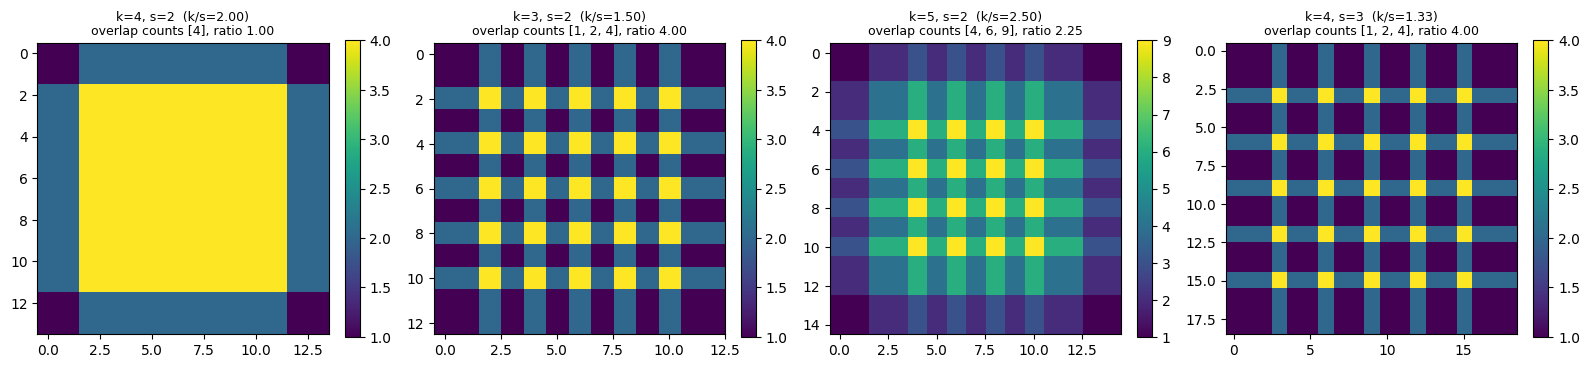

In [3]:
# ============================================================
# 図: 重なりのパターン（学習ゼロ）
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(16, 4.0))
for ax, (k, s) in zip(axes, [(4, 2), (3, 2), (5, 2), (4, 3)]):
    y, u = overlap_counts(k, s, n_in=6)
    im = ax.imshow(y.numpy(), cmap="viridis")
    ax.set_title(f"k={k}, s={s}  (k/s={k / s:.2f})\n"
                 f"overlap counts {[int(v) for v in u]}, ratio {max(u) / min(u):.2f}",
                 fontsize=9)
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### 設計への帰結 — なぜ 16x16 にするか

本章は MNIST を **16x16** に揃えます。28x28 や 14x14 ではなく 16x16 を選んだのは
上の表の帰結です。

ストライド 2 で空間サイズを 1 → 4 → 8 → 16 と倍にしていくなら、
全部の層で $k=4, s=2$（倍数）が使えます。

ところが 14x14 を作ろうとすると途中で **7** を通る必要があり、
ストライド 2 で奇数サイズを作るには

$$(4-1)\cdot 2 - 2p + k = 7 \;\Longrightarrow\; k = 2p + 1 \quad (\text{奇数})$$

となって、**$k$ が $s$ の倍数になりません**。
つまり「14x14 の DCGAN」は、市松模様の種を1層必ず含みます。

> 画像サイズを 2 のべき乗に揃えるのは見栄えの問題ではなく、
> **全層で $k$ が $s$ の倍数になるようにするため**です。

In [4]:
# ============================================================
# MNIST を 16x16 に揃えて読み込む
# ============================================================

candidates = ["data", "notebooks/generative/data", "../generative/data",
              os.path.join(os.getcwd(), "data")]
data_root = None
for c in candidates:
    if os.path.isdir(os.path.join(c, "MNIST")):
        data_root = c
        break
if data_root is None:
    raise FileNotFoundError(f"MNIST が見つかりません。探した場所: {candidates}")
print("MNIST の場所:", data_root)


def prepare(d):
    X = (d.data.float() / 255.0)[:, None]
    X = F.pad(X, (2, 2, 2, 2))                 # 28 -> 32
    return F.avg_pool2d(X, 2) * 2 - 1, d.targets   # 16x16, [-1, 1]（tanh 用）


X_train, Y_train = prepare(datasets.MNIST(root=data_root, train=True, download=False))
X_test, Y_test = prepare(datasets.MNIST(root=data_root, train=False, download=False))

# ★ テストセットを並べ替える（理由は第3節のつまずき）
_p = torch.randperm(len(X_test), generator=torch.Generator().manual_seed(7))
X_test, Y_test = X_test[_p], Y_test[_p]

print(f"学習 {tuple(X_train.shape)}  テスト {tuple(X_test.shape)}  "
      f"範囲 [{float(X_train.min()):.1f}, {float(X_train.max()):.1f}]")

MNIST の場所: notebooks/generative/data


学習 (60000, 1, 16, 16)  テスト (10000, 1, 16, 16)  範囲 [-1.0, 1.0]


<a id="metrics"></a>
## 3. 画像をどう測るか

182-184 では真の分布（8峰リング）が分かっていたので、
占有率・最近傍距離・エネルギー距離を**直接**計算できました。
画像ではそれができません。

### 分類器を特徴抽出器にする

FID（Fréchet Inception Distance）の本質は、
**「特徴空間で2つのガウス近似の間の距離を測る」**ことです（182 第4節）。
本物の FID は ImageNet で学習した Inception を使いますが、原理はこうです。

$$\mathrm{FID} = \lVert \mu_1 - \mu_2 \rVert^2
+ \mathrm{tr}\big(\Sigma_1 + \Sigma_2 - 2(\Sigma_1\Sigma_2)^{1/2}\big)$$

MNIST なので、小さな分類器を自分で学習させて特徴抽出器にします。
これで4つの指標が作れます。

| 指標 | 何を測るか | 真のデータでの値 |
|---|---|---|
| クラス占有率の最大偏差 | 10クラスがどれだけ均等に出るか（182 の占有率の画像版） | 0 に近い |
| 分類器の平均確信度 | 生成画像が「はっきりした数字」になっているか | 0.98 程度 |
| 特徴空間の FID | 分布全体のずれ | **測って決める** |
| 市松指標 | $(i \bmod 2, j \bmod 2)$ の4群の平均の広がり ÷ 全画素の標準偏差 | 0 に近い |

最後の市松指標は本章用に作りました。市松模様があれば画素の偶奇で平均が変わるので、
その広がりを見ます。

In [5]:
# ============================================================
# 分類器を学習して特徴抽出器にする
# ============================================================

class Classifier(nn.Module):
    def __init__(self, ch=32):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(1, ch, 3, 2, 1), nn.ReLU(),          # 8x8
            nn.Conv2d(ch, ch * 2, 3, 2, 1), nn.ReLU(),     # 4x4
            nn.Flatten(), nn.Linear(ch * 2 * 16, 64), nn.ReLU())
        self.head = nn.Linear(64, 10)

    def feat(self, x):
        return self.body(x)

    def forward(self, x):
        return self.head(self.body(x))


def train_classifier(steps=1500, seed=0, batch=256):
    torch.manual_seed(seed)
    C = Classifier()
    opt = torch.optim.Adam(C.parameters(), lr=1e-3)
    for _ in range(steps):
        j = torch.randint(0, len(X_train), (batch,))
        opt.zero_grad()
        F.cross_entropy(C(X_train[j]), Y_train[j]).backward()
        opt.step()
    C.eval()
    return C


t0 = time.time()
CLF = train_classifier()
with torch.no_grad():
    acc = (torch.cat([CLF(X_test[i:i + 2000]).argmax(1)
                      for i in range(0, len(X_test), 2000)]) == Y_test).float().mean()
print(f"分類器: 16x16 でのテスト精度 {float(acc):.4f}   学習 {time.time() - t0:.0f}s")


@torch.no_grad()
def features(X, bs=2000):
    return torch.cat([CLF.feat(X[i:i + bs]) for i in range(0, len(X), bs)])


@torch.no_grad()
def class_logits(X, bs=2000):
    return torch.cat([CLF(X[i:i + bs]) for i in range(0, len(X), bs)])


REF_FEAT = features(X_test[:5000])
# 死んだ ReLU 次元（常にゼロ）を落とす。残すと共分散が特異になる
LIVE = REF_FEAT.std(0) > 1e-8
print(f"特徴 64 次元のうち分散を持つ次元: {int(LIVE.sum())}")
_ev = np.linalg.eigvalsh(np.cov(REF_FEAT.numpy().astype(np.float64), rowvar=False))
print(f"落とさない場合の共分散: 最小固有値 {_ev[0]:.2e}（負）、"
      f"最大の 1e-6 倍未満の個数 {int((_ev < _ev[-1] * 1e-6).sum())}")

分類器: 16x16 でのテスト精度 0.9802   学習 31s
特徴 64 次元のうち分散を持つ次元: 44
落とさない場合の共分散: 最小固有値 -1.57e-14（負）、最大の 1e-6 倍未満の個数 20


In [6]:
# ============================================================
# 4つの指標
# ============================================================

def fid_feature(A, B):
    A = A[:, LIVE].numpy().astype(np.float64)
    B = B[:, LIVE].numpy().astype(np.float64)
    m1, m2 = A.mean(0), B.mean(0)
    C1, C2 = np.cov(A, rowvar=False), np.cov(B, rowvar=False)
    cc = sqrtm(C1 @ C2)
    if np.iscomplexobj(cc):
        cc = cc.real            # 行列平方根は数値的に微小な虚部を持つ
    return float(((m1 - m2) ** 2).sum() + np.trace(C1 + C2 - 2 * cc))


def checkerboard(X):
    # (i%2, j%2) の4群の平均の広がり / 全画素の標準偏差
    g = [X[:, :, i::2, j::2].mean() for i in range(2) for j in range(2)]
    return float(torch.stack(g).std() / X.std())


def image_metrics(S):
    p = class_logits(S).softmax(-1)
    occ = torch.bincount(p.argmax(-1), minlength=10).float() / len(S)
    return dict(fid=fid_feature(features(S), REF_FEAT),
                maxdev=float((occ - 0.1).abs().max()),
                conf=float(p.max(-1).values.mean()),
                chk=checkerboard(S), occ=occ.numpy())


print("基準（真のデータ）")
print(f"{'データ':<24}{'FID':>9}{'占有率最大偏差':>14}{'確信度':>9}{'市松':>10}")
print("-" * 66)
base_rows = []
for tag, S in [("test[5000:10000]", X_test[5000:10000]),
               ("train[:5000]", X_train[:5000])]:
    m = image_metrics(S)
    base_rows.append((tag, m))
    print(f"{tag:<24}{m['fid']:9.4f}{m['maxdev']:14.4f}{m['conf']:9.4f}{m['chk']:10.5f}")
print("-" * 66)
print("-> FID の雑音床（完璧なモデルが出す値）はこの1行目。これより小さい差は比べられない")

基準（真のデータ）
データ                           FID       占有率最大偏差      確信度        市松
------------------------------------------------------------------


test[5000:10000]           0.5294        0.0184   0.9800   0.00254


train[:5000]               1.2912        0.0130   0.9804   0.00187
------------------------------------------------------------------
-> FID の雑音床（完璧なモデルが出す値）はこの1行目。これより小さい差は比べられない


### つまずき — FID の基準値が、並べ方だけで 27 倍変わった

最初はテストセットを**そのまま**使って参照を作りました。
`X_test[:5000]` を参照、`X_test[5000:10000]` を「完璧なモデル」として FID を測ると
**12.99** になりました。ところが**学習データ** 5000 枚のほうが **5.21** で、
テストデータ同士より良いという逆転が起きました。

共分散が特異（固有値の 25/64 がゼロ）だったので最初はそれを疑いましたが、
特徴を低次元に射影しても逆転は残りました。

| 特徴の次元 | test[5k:10k] | train[:5k] | train[5k:10k] |
|---|---|---|---|
| 64 | 12.9873 | 5.2108 | 5.6620 |
| 32 | 12.8491 | 5.1446 | 5.6072 |
| 16 | 11.2838 | 4.4549 | 4.9338 |
| 8 | 8.0600 | 3.1585 | 3.4852 |

原因は **MNIST のテストセットが均質でない**ことでした。

| | 分類器の精度 |
|---|---|
| test[:5000] | 0.9712 |
| test[5000:10000] | **0.9884** |
| train[:5000] | 0.9832 |

前半のほうが 1.7 ポイント難しい。クラス構成はほぼ同じ（最大偏差 0.0142 / 0.0128）なので
クラスの偏りではなく、**書き手の構成が違う**のです。

テストセットを並べ替えてから前半と後半に分けると

| | FID |
|---|---|
| 並べ替え前（test[:5k] vs test[5k:]） | **12.9873** |
| 並べ替え後 | **0.4740** |

**27 倍**です。並べ替えないと、FID 13 以下の差は全部雑音に埋もれます。

> 参照データは必ず無作為化する。「公開データセットの既定の順序」を信用しない。
> そして**雑音床を自分で測る**（184 第7節と同じ規律）。

<a id="ablation"></a>
## 4. DCGAN の経験則を1つずつ外す

DCGAN 原論文のガイドラインは次の5つです。

| # | ガイドライン | 本章での外し方 |
|---|---|---|
| 1 | プーリングを使わず、ストライド付き畳み込みで縮小・拡大する | D を MaxPool で縮める |
| 2 | 生成器と判別器に BatchNorm を入れる | G の BN を外す / D の BN を外す |
| 3 | 深い構成では全結合の隠れ層を無くす | G の入力側に全結合層を足す |
| 4 | 生成器は ReLU（出力層だけ tanh） | （本章では固定） |
| 5 | 判別器は LeakyReLU | D を ReLU にする |

> **ここで予測を立てます。** BatchNorm を外すと大きく悪化し（2 がいちばん効く）、
> 全結合層の追加は小さい影響、MaxPool は中くらい、
> D の ReLU は 180 で測った勾配消失を悪化させるので効くはず。
> この予測は**当たりませんでした**（結果は下）。

In [7]:
# ============================================================
# DCGAN の生成器と判別器（経験則を切り替えられるようにする）
# ============================================================

NZ = 32


class Generator(nn.Module):
    # 1x1 -> 4x4 -> 8x8 -> 16x16。全層 k=4, s=2（k が s の倍数）
    def __init__(self, ch=32, bn=True, fc=False, last="ct4"):
        super().__init__()
        N = (lambda c: nn.BatchNorm2d(c)) if bn else (lambda c: nn.Identity())
        self.fc = (nn.Sequential(nn.Flatten(), nn.Linear(NZ, NZ), nn.ReLU(),
                                 nn.Unflatten(1, (NZ, 1, 1)))
                   if fc else nn.Identity())
        last_layer = {
            "ct4": nn.ConvTranspose2d(ch * 2, 1, 4, 2, 1, bias=False),
            "ct3": nn.ConvTranspose2d(ch * 2, 1, 3, 2, 1, output_padding=1, bias=False),
            "up": nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                                nn.Conv2d(ch * 2, 1, 3, 1, 1, bias=False)),
        }[last]
        self.net = nn.Sequential(
            nn.ConvTranspose2d(NZ, ch * 4, 4, 1, 0, bias=False), N(ch * 4), nn.ReLU(),
            nn.ConvTranspose2d(ch * 4, ch * 2, 4, 2, 1, bias=False), N(ch * 2), nn.ReLU(),
            last_layer, nn.Tanh())

    def forward(self, a, gen=None):
        # gen を渡せるようにする。指標を比べるときはサンプリングも決定的にしたい
        z = (torch.randn(a, NZ, 1, 1, generator=gen) if isinstance(a, int) else a)
        return self.net(self.fc(z))


class Discriminator(nn.Module):
    def __init__(self, ch=32, bn=True, act="lrelu", down="stride"):
        super().__init__()
        A = (lambda: nn.LeakyReLU(0.2)) if act == "lrelu" else (lambda: nn.ReLU())
        N = (lambda c: nn.BatchNorm2d(c)) if bn else (lambda c: nn.Identity())
        if down == "stride":
            l1 = nn.Conv2d(1, ch, 4, 2, 1, bias=False)
            l2 = nn.Conv2d(ch, ch * 2, 4, 2, 1, bias=False)
        else:   # プーリングで縮める（DCGAN が避けた方法）
            l1 = nn.Sequential(nn.Conv2d(1, ch, 3, 1, 1, bias=False), nn.MaxPool2d(2))
            l2 = nn.Sequential(nn.Conv2d(ch, ch * 2, 3, 1, 1, bias=False), nn.MaxPool2d(2))
        self.net = nn.Sequential(l1, A(), l2, N(ch * 2), A(),
                                 nn.Conv2d(ch * 2, 1, 4, 1, 0, bias=False))

    def forward(self, x):
        return self.net(x).flatten(1).squeeze(-1)


bce = nn.BCEWithLogitsLoss()

def train_dcgan(steps=1000, seed=0, batch=128, lr=2e-4, gkw=None, dkw=None):
    torch.manual_seed(seed)
    G = Generator(**(gkw or {}))
    D = Discriminator(**(dkw or {}))
    og = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    for _ in range(steps):
        x_real = X_train[torch.randint(0, len(X_train), (batch,))]
        x_fake = G(batch).detach()
        od.zero_grad()
        (bce(D(x_real), torch.ones(batch))
         + bce(D(x_fake), torch.zeros(batch))).backward()
        od.step()
        og.zero_grad()
        bce(D(G(batch)), torch.ones(batch)).backward()
        og.step()
    return G, D


@torch.no_grad()
def sample_images(G, n=5000, train_mode=False, seed=1234, batch=500):
    # ★ 既定でサンプリングも決定的にする。そうしないと FID が再実行で動き、
    #   表に書いた数値と合わなくなる（その動く幅は第6節で測る）
    was = G.training
    G.train(train_mode)
    gen = torch.Generator().manual_seed(seed)
    out = torch.cat([G(min(batch, n - i), gen=gen) for i in range(0, n, batch)])
    G.train(was)
    return out

print("定義完了")

定義完了


In [8]:
# ============================================================
# 経験則を1つずつ外す（6構成 × 2シード。CPU で約10分）
# ============================================================

CONFIGS = [
    ("A 基準（経験則どおり）", {}, {}),
    ("B G の BatchNorm なし", {"bn": False}, {}),
    ("C D の BatchNorm なし", {}, {"bn": False}),
    ("D D を ReLU にする", {}, {"act": "relu"}),
    ("E G に全結合の隠れ層", {"fc": True}, {}),
    ("F D を MaxPool で縮める", {}, {"down": "pool"}),
]
ABL_SEEDS = [0, 1]

t0 = time.time()
abl_res, abl_G = {}, {}
print(f"{'構成':<24}{'FID':>9}{'占有率最大偏差':>14}{'確信度':>9}{'市松':>10}")
print("-" * 66)
for tag, gkw, dkw in CONFIGS:
    ms = []
    for s in ABL_SEEDS:
        G, _ = train_dcgan(steps=1000, seed=s, gkw=gkw, dkw=dkw)
        if s == 0:
            abl_G[tag] = G
        ms.append(image_metrics(sample_images(G)))
    abl_res[tag] = ms
    f = lambda k: np.array([m[k] for m in ms])
    print(f"{tag:<24}{f('fid').mean():9.3f}{f('maxdev').mean():14.4f}"
          f"{f('conf').mean():9.4f}{f('chk').mean():10.5f}")
print("-" * 66)
print(f"2シードの平均。経過 {time.time() - t0:.0f}s")
print(f"基準（真のデータ）: FID {base_rows[0][1]['fid']:.4f}  "
      f"占有率最大偏差 {base_rows[0][1]['maxdev']:.4f}  "
      f"確信度 {base_rows[0][1]['conf']:.4f}  市松 {base_rows[0][1]['chk']:.5f}")
print()
print("シードごとの値")
for tag, ms in abl_res.items():
    f = lambda k: np.array([m[k] for m in ms])
    print(f"  {tag:<24} FID {np.round(f('fid'), 2)}  "
          f"最大偏差 {np.round(f('maxdev'), 4)}  確信度 {np.round(f('conf'), 4)}")

構成                            FID       占有率最大偏差      確信度        市松
------------------------------------------------------------------


A 基準（経験則どおり）               33.235        0.0612   0.8083   0.06044


B G の BatchNorm なし         55.712        0.1103   0.7725   0.02510


C D の BatchNorm なし         75.239        0.1233   0.7809   0.03404


D D を ReLU にする             17.121        0.0643   0.8437   0.02341


E G に全結合の隠れ層              301.502        0.3100   0.7729   0.03754


F D を MaxPool で縮める         20.102        0.0503   0.8539   0.00437
------------------------------------------------------------------
2シードの平均。経過 797s
基準（真のデータ）: FID 0.5294  占有率最大偏差 0.0184  確信度 0.9800  市松 0.00254

シードごとの値
  A 基準（経験則どおり）             FID [33.78 32.69]  最大偏差 [0.0636 0.0588]  確信度 [0.8017 0.815 ]
  B G の BatchNorm なし       FID [59.01 52.42]  最大偏差 [0.1188 0.1018]  確信度 [0.7794 0.7656]
  C D の BatchNorm なし       FID [81.58 68.9 ]  最大偏差 [0.1502 0.0964]  確信度 [0.7877 0.7741]
  D D を ReLU にする           FID [17.79 16.45]  最大偏差 [0.0786 0.05  ]  確信度 [0.8429 0.8446]
  E G に全結合の隠れ層             FID [372.42 230.59]  最大偏差 [0.285 0.335]  確信度 [0.7718 0.7741]
  F D を MaxPool で縮める       FID [18.09 22.12]  最大偏差 [0.0476 0.053 ]  確信度 [0.8574 0.8504]


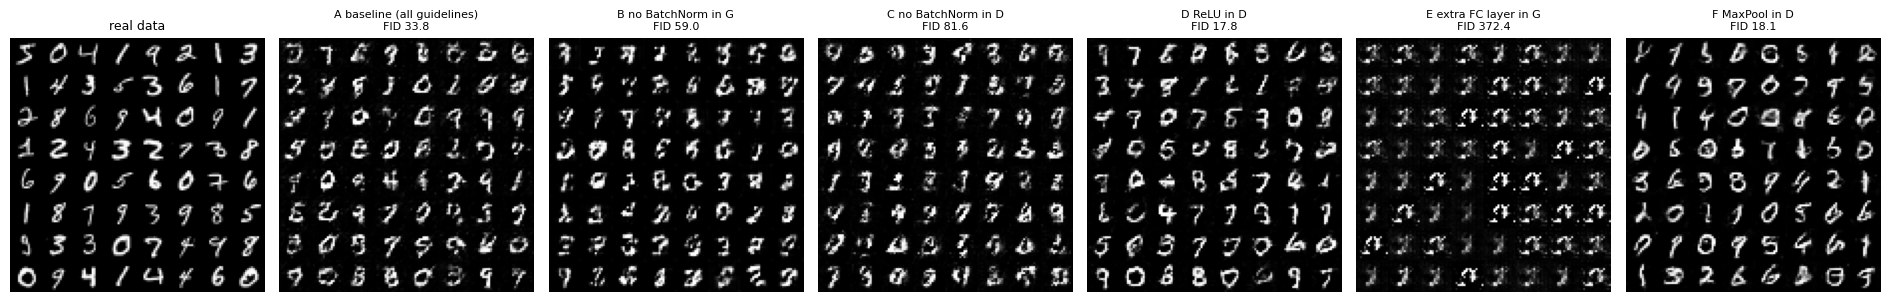

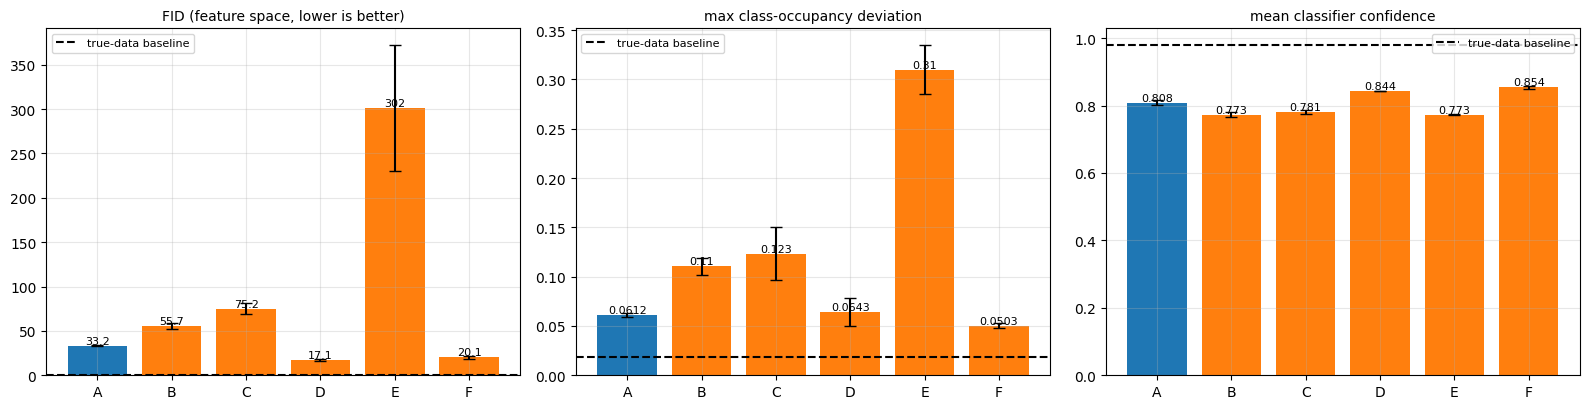

In [9]:
# ============================================================
# 図: 生成画像と指標
# ============================================================

names_en = {"A 基準（経験則どおり）": "A baseline (all guidelines)",
            "B G の BatchNorm なし": "B no BatchNorm in G",
            "C D の BatchNorm なし": "C no BatchNorm in D",
            "D D を ReLU にする": "D ReLU in D",
            "E G に全結合の隠れ層": "E extra FC layer in G",
            "F D を MaxPool で縮める": "F MaxPool in D"}

fig, axes = plt.subplots(1, 7, figsize=(19, 3.0))
real = X_train[:64]
grid = real.reshape(8, 8, 16, 16).permute(0, 2, 1, 3).reshape(128, 128)
axes[0].imshow(grid.numpy(), cmap="gray", vmin=-1, vmax=1)
axes[0].set_title("real data", fontsize=9)
axes[0].axis("off")
for ax, (tag, _, _) in zip(axes[1:], CONFIGS):
    S = sample_images(abl_G[tag], n=64)
    grid = S.reshape(8, 8, 16, 16).permute(0, 2, 1, 3).reshape(128, 128)
    ax.imshow(grid.numpy(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"{names_en[tag]}\nFID {abl_res[tag][0]['fid']:.1f}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
tags = [t for t, _, _ in CONFIGS]
xs = range(len(tags))
labels = [names_en[t].split(" ", 1)[0] for t in tags]
for ax, (key, title, ref) in zip(axes, [
        ("fid", "FID (feature space, lower is better)", base_rows[0][1]["fid"]),
        ("maxdev", "max class-occupancy deviation", base_rows[0][1]["maxdev"]),
        ("conf", "mean classifier confidence", base_rows[0][1]["conf"])]):
    vals = [np.mean([m[key] for m in abl_res[t]]) for t in tags]
    errs = [np.ptp([m[key] for m in abl_res[t]]) / 2 for t in tags]
    ax.bar(xs, vals, yerr=errs, capsize=4,
           color=["tab:blue"] + ["tab:orange"] * 5)
    ax.axhline(ref, color="k", ls="--", lw=1.5, label="true-data baseline")
    ax.set_xticks(list(xs))
    ax.set_xticklabels(labels)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.3g}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

### 読み取れること

#### 予測は3つ当たり、2つ外れた

| 構成 | FID（2シード平均） | シードごと | 占有率最大偏差 | 確信度 |
|---|---|---|---|---|
| A 基準（経験則どおり） | 33.235 | 33.78 / 32.69 | 0.0612 | 0.8083 |
| B G の BatchNorm なし | 55.712 | 59.01 / 52.42 | 0.1103 | 0.7725 |
| C D の BatchNorm なし | 75.239 | 81.58 / 68.90 | 0.1233 | 0.7809 |
| **D D を ReLU にする** | **17.121** | 17.79 / 16.45 | 0.0643 | 0.8437 |
| E G に全結合の隠れ層 | **301.502** | 372.42 / 230.59 | 0.3100 | 0.7729 |
| **F D を MaxPool で縮める** | **20.102** | 18.09 / 22.12 | 0.0503 | 0.8539 |
| 基準（真のデータ） | 0.5294 | — | 0.0184 | 0.9800 |

**当たった3つ**

- BatchNorm を外すと悪化する（B は 1.7 倍、C は 2.3 倍）
- **判別器の BatchNorm のほうが生成器より効く**（75.2 対 55.7）
- 全結合の隠れ層は致命的（**9.1 倍**悪化、占有率の最大偏差 0.3100 = 1クラスに大きく偏る）

**外れた2つ — 経験則を破ったほうが良くなった**

| | FID | 基準との比 | シードの範囲が基準と重なるか |
|---|---|---|---|
| D 判別器を ReLU（ガイドライン5違反） | 17.121 | **1.9 倍良い** | 重ならない（17.79-16.45 対 33.78-32.69） |
| F 判別器を MaxPool（ガイドライン1違反） | 20.102 | **1.7 倍良い** | 重ならない（18.09-22.12 対 33.78-32.69） |

182 の教訓（ばらつきより小さい差を読まない）に従ってシードごとの範囲を見ましたが、
**どちらも基準と重なりません**。偶然ではありません。

しかも F の市松指標は 0.00437 で、**真のデータの 0.00254 に最も近い**。
生成器は何も変えていないのに、です。これは第5節で追いかけます。

#### どう読むべきか — 経験則は規模に依存する

DCGAN 原論文は 2016 年に **64x64 の LSUN / ImageNet** で、
本章よりはるかに長く学習して得られた経験則です。
本章は **16x16 の MNIST・1000 歩**です。

> 「DCGAN のガイドラインは間違っている」ではありません。
> **この規模・この学習量では2つが逆転する**、が測ったことです。

ありそうな反論は「1000 歩が短すぎる。ガイドラインは長期の安定性の話だ」です。
これは測れるので、第5節の後で 2500 歩まで伸ばして確かめます。

#### 指標ごとに順位が違う（182 の再現）

FID では D（17.1）< F（20.1）ですが、占有率の最大偏差では F（0.0503）< D（0.0643）。
**順位が入れ替わります。**

確信度はもっと鈍い。B（0.7725）と E（0.7729）はほぼ同じなのに、
FID は 55.7 と 301.5 で **5.4 倍**違います。
確信度は「はっきりした数字に見えるか」しか見ないので、
E の崩壊（1クラスに偏る）を**見逃します**。

> 画像でも 182 の結論がそのまま効きます。1つの指標で順位を決めてはいけない。

<a id="checkerboard-trained"></a>
## 5. 市松模様は誰が作るのか

第2節で、$k$ が $s$ の倍数なら重なりが一様になることを**学習前に**確かめました。
素直な予想は「生成器の最終層が $k=4, s=2$（倍数）なら市松模様は出ない」です。

ところが第4節の表を見てください。基準構成（最終層は $k=4, s=2$）の市松指標は
**0.06000** で、真のデータの 0.003 の **20 倍**です。一様な重なりなのに市松模様が出ています。

しかも F（判別器を MaxPool にしただけ）の市松指標は **0.00492** — 真のデータに迫ります。
**生成器は何も変えていないのに**です。

> **仮説**: 市松模様を決めているのは生成器の最終層ではなく**判別器の縮小方法**。
> ストライド 2 の畳み込みは固定の偶奇格子だけを見るので、
> 偶奇で明るさが違っても**罰を与えられない**。
> MaxPool は偶奇をまたいで取るので検出できる。

生成器の最終層3通り × 判別器の縮小2通りの **6 組**で切り分けます。

In [10]:
# ============================================================
# 市松模様: G の最終層 × D の縮小方法（6組）
# ============================================================

# 基準構成（ct4 × stride）と F（ct4 × pool）は第4節で学習済みなので再利用する
LASTS = [("k=4,s=2（倍数）", "ct4"), ("k=3,s=2（非倍数）", "ct3"), ("補間+conv", "up")]
DOWNS = [("stride", "stride"), ("MaxPool", "pool")]
reuse = {("ct4", "stride"): abl_G["A 基準（経験則どおり）"],
         ("ct4", "pool"): abl_G["F D を MaxPool で縮める"]}

t0 = time.time()
cross = {}
hdr = (f"{'G の最終層':<20}{'D の縮小':<10}{'市松':>9}{'全画素std':>11}"
       f"{'(0,0)':>9}{'(0,1)':>9}{'(1,0)':>9}{'(1,1)':>9}{'FID':>9}")
print(hdr)
print("-" * len(hdr))
for lname, last in LASTS:
    for dname, down in DOWNS:
        G = reuse.get((last, down))
        if G is None:
            G, _ = train_dcgan(steps=1000, seed=0,
                               gkw={"last": last}, dkw={"down": down})
        S = sample_images(G, 5000)
        g = [float(S[:, :, i::2, j::2].mean()) for i in range(2) for j in range(2)]
        m = image_metrics(S)
        cross[(last, down)] = (m, g, float(S.std()), G)
        print(f"{lname:<20}{dname:<10}{m['chk']:9.5f}{float(S.std()):11.4f}"
              + "".join(f"{v:9.4f}" for v in g) + f"{m['fid']:9.3f}")
S = X_train[:5000]
g = [float(S[:, :, i::2, j::2].mean()) for i in range(2) for j in range(2)]
print(f"{'真のデータ':<30}{checkerboard(S):9.5f}{float(S.std()):11.4f}"
      + "".join(f"{v:9.4f}" for v in g))
print("-" * len(hdr))
print(f"経過 {time.time() - t0:.0f}s")
print()
print("市松指標の平均（どちらの因子が効くか）")
for lname, last in LASTS:
    vals = [cross[(last, d)][0]["chk"] for _, d in DOWNS]
    print(f"  G の最終層 {lname:<18} の平均 {np.mean(vals):.5f}")
for dname, down in DOWNS:
    vals = [cross[(l, down)][0]["chk"] for _, l in LASTS]
    print(f"  D の縮小   {dname:<18} の平均 {np.mean(vals):.5f}")

G の最終層              D の縮小            市松     全画素std    (0,0)    (0,1)    (1,0)    (1,1)      FID
-----------------------------------------------------------------------------------------------


k=4,s=2（倍数）         stride      0.05366     0.4786  -0.7607  -0.7800  -0.8192  -0.8030   33.783


k=4,s=2（倍数）         MaxPool     0.00447     0.5087  -0.7795  -0.7798  -0.7802  -0.7843   18.086


k=3,s=2（非倍数）        stride      0.02080     0.4856  -0.7761  -0.7991  -0.7931  -0.7950   32.872


k=3,s=2（非倍数）        MaxPool     0.00600     0.4883  -0.7986  -0.8017  -0.7946  -0.7986   18.696


補間+conv             stride      0.00470     0.5257  -0.7733  -0.7774  -0.7718  -0.7757   23.180


補間+conv             MaxPool     0.00101     0.4795  -0.8100  -0.8100  -0.8091  -0.8093   15.952
真のデータ                           0.00187     0.5013  -0.7994  -0.8007  -0.8007  -0.8016
-----------------------------------------------------------------------------------------------
経過 323s

市松指標の平均（どちらの因子が効くか）
  G の最終層 k=4,s=2（倍数）        の平均 0.02906
  G の最終層 k=3,s=2（非倍数）       の平均 0.01340
  G の最終層 補間+conv            の平均 0.00286
  D の縮小   stride             の平均 0.02639
  D の縮小   MaxPool            の平均 0.00382


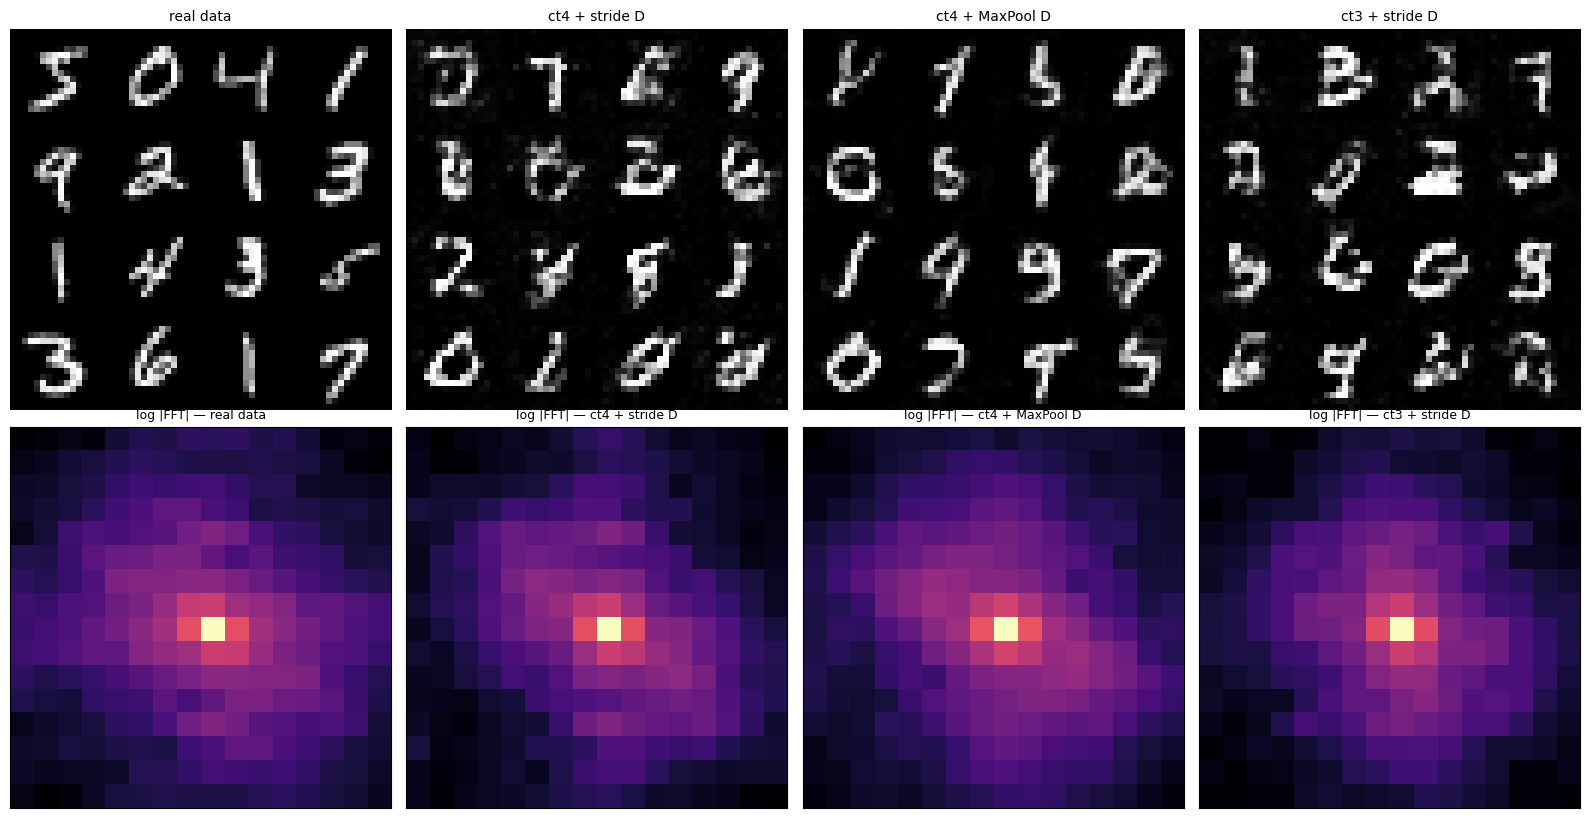

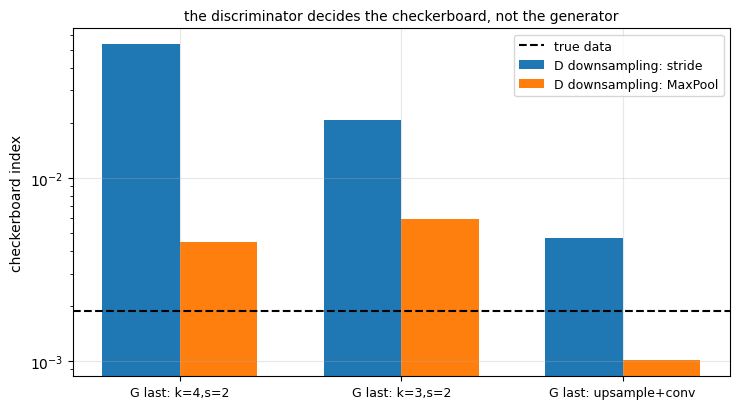

In [11]:
# ============================================================
# 図: 市松模様を画像とスペクトルで見る
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(16, 8.2))
show = [("real data", X_train[:16]),
        ("ct4 + stride D", sample_images(cross[("ct4", "stride")][3], n=16)),
        ("ct4 + MaxPool D", sample_images(cross[("ct4", "pool")][3], n=16)),
        ("ct3 + stride D", sample_images(cross[("ct3", "stride")][3], n=16))]
for ax, (ttl, S) in zip(axes[0], show):
    grid = S[:16].reshape(4, 4, 16, 16).permute(0, 2, 1, 3).reshape(64, 64)
    ax.imshow(grid.numpy(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(ttl, fontsize=10)
    ax.axis("off")
# 2次元フーリエ振幅。偶奇の周期はナイキスト（スペクトルの四隅＝中心からの最遠）に出る
for ax, (ttl, S) in zip(axes[1], show):
    Ff = torch.fft.fftshift(torch.fft.fft2(S[:, 0]), dim=(-2, -1)).abs().mean(0)
    ax.imshow(torch.log1p(Ff).numpy(), cmap="magma")
    ax.set_title(f"log |FFT| — {ttl}", fontsize=9)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
w = 0.35
xs = np.arange(len(LASTS))
for i, (dname, down) in enumerate(DOWNS):
    vals = [cross[(l, down)][0]["chk"] for _, l in LASTS]
    ax.bar(xs + (i - 0.5) * w, vals, w, label=f"D downsampling: {dname}")
ax.axhline(checkerboard(X_train[:5000]), color="k", ls="--", lw=1.5,
           label="true data")
ax.set_xticks(xs)
ax.set_xticklabels(["G last: k=4,s=2", "G last: k=3,s=2", "G last: upsample+conv"],
                   fontsize=9)
ax.set_ylabel("checkerboard index")
ax.set_yscale("log")
ax.set_title("the discriminator decides the checkerboard, not the generator", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 読み取れること

#### 市松模様を支配しているのは判別器だった

| G の最終層 | D の縮小 | 市松指標 | FID |
|---|---|---|---|
| k=4, s=2（倍数） | stride | **0.05366** | 33.783 |
| k=4, s=2（倍数） | MaxPool | **0.00447** | 18.086 |
| k=3, s=2（非倍数） | stride | 0.02080 | 32.872 |
| k=3, s=2（非倍数） | MaxPool | 0.00600 | 18.696 |
| 補間 + conv | stride | 0.00470 | 23.180 |
| 補間 + conv | MaxPool | **0.00101** | **15.952** |
| 真のデータ | — | 0.00187 | — |

因子ごとの平均を取ると

| 因子 | 平均の市松指標 |
|---|---|
| D の縮小 = stride | 0.02639 |
| D の縮小 = MaxPool | **0.00382**（6.9 分の1） |
| G の最終層 = k=4,s=2 | 0.02906 |
| G の最終層 = k=3,s=2 | 0.01340 |
| G の最終層 = 補間+conv | 0.00286 |

**生成器を1つも変えずに**、判別器の縮小方法だけを stride から MaxPool に替えると
市松指標が 0.05366 → 0.00447（**12 倍**）落ちます。
偶奇4群の平均を直接見ても分かります。

| 構成 | (0,0) | (0,1) | (1,0) | (1,1) | 幅 |
|---|---|---|---|---|---|
| k=4,s=2 + stride D | -0.7607 | -0.7800 | -0.8192 | -0.8030 | **0.059** |
| k=4,s=2 + MaxPool D | -0.7795 | -0.7798 | -0.7802 | -0.7843 | 0.005 |
| 真のデータ | -0.7994 | -0.8007 | -0.8007 | -0.8016 | 0.002 |

**機構**: ストライド 2 の畳み込みは、入力の**固定された偶奇格子**の上だけを見ます。
だから偶奇で明るさが 0.059 違っても、判別器の受容野の中では見分けがつきません。
**罰を与えられないものは直りません。** MaxPool は 2x2 の窓で偶奇をまたいで取るので、
偶奇の差が出力に伝わり、生成器が罰を受けます。

#### 第2節の厳密計算は、学習後の結果を予測しなかった

学習前の重なりの計算（第2節）では

| | 重なりの比 |
|---|---|
| k=4, s=2 | **1.00（一様）** |
| k=3, s=2 | 4.00 |

素直な予想は「k=4 のほうが市松模様が出ない」です。**逆でした。**
stride の判別器では k=4 が 0.05366 で、k=3 の 0.02080 より **2.6 倍悪い**。

しかも MaxPool の判別器にすると順位が入れ替わります（k=4 の 0.00447 < k=3 の 0.00600）。
**生成器の最終層の効果は、判別器の縮小方法によって符号が変わります。**

> 学習前に厳密に計算できる量（重なりの一様性）は、
> 学習後に出る模様の**必要条件でも十分条件でもありませんでした**。
> 一様な重なりが保証するのは「学習ゼロの状態で模様が無い」ことだけです。
> 学習後の重みは、一様な重なりの上に模様を**作れます**し、
> 不均一な重なりを**打ち消せます**。

これは本章でいちばん重要な外れです。「転置畳み込みが市松模様の原因」という
よく見る説明は、**原因を生成器の側に置いている点で誤解を招きます**。
測った限りでは、主因は判別器が偶奇を見られるかどうかでした。

#### 定番の対処（補間 + 畳み込み）は効く。ただし理由が違う

補間 + conv は市松指標 0.00470（stride D）/ 0.00101（MaxPool D）で最も低く、
MaxPool と組むと**真のデータの 0.00187 を下回ります**（= 雑音床に達した）。
FID も 15.952 で全構成中最良です。

対処としては正しいのですが、上の分析からすると
「転置畳み込みをやめたから効いた」というより
「補間が偶奇を混ぜるので、どの判別器でも模様が残りにくい」と読むべきです。

### 逆転した経験則は、長く学習しても逆転したままか

第4節で D（判別器を ReLU）と F（判別器を MaxPool）が基準より良くなりました。
ありそうな反論は「1000 歩が短すぎる。ガイドラインは長期の安定性の話だ」です。

2500 歩まで伸ばして同じ3構成を比べます。

In [12]:
# ============================================================
# 1000歩 と 2500歩 で順位が変わるか（2シード）
# ============================================================

t0 = time.time()
LONG = [("A 基準", {}, {}),
        ("D D を ReLU", {}, {"act": "relu"}),
        ("F D を MaxPool", {}, {"down": "pool"})]
print(f"{'構成':<20}{'1000歩':>10}{'2500歩':>10}{'2500歩のシードごと':>26}")
print("-" * 66)
long_res = []
for tag, gkw, dkw in LONG:
    f1 = [np.mean([m["fid"] for m in abl_res[t]])
          for t in abl_res if t.startswith(tag.split()[0])][0]
    f25 = []
    for s in [0, 1]:
        G, _ = train_dcgan(steps=2500, seed=s, gkw=gkw, dkw=dkw)
        f25.append(image_metrics(sample_images(G))["fid"])
    long_res.append((tag, f1, f25))
    print(f"{tag:<20}{f1:10.2f}{np.mean(f25):10.2f}"
          f"{str(np.round(f25, 2).tolist()):>26}")
print("-" * 66)
print(f"経過 {time.time() - t0:.0f}s")
print()
for tag, f1, f25 in long_res:
    print(f"  {tag:<20} 1000歩 {f1:7.2f} -> 2500歩 {np.mean(f25):7.2f}  "
          f"({f1 / np.mean(f25):.2f}倍改善)")

構成                       1000歩     2500歩               2500歩のシードごと
------------------------------------------------------------------


A 基準                     33.23     10.37              [11.5, 9.23]


D D を ReLU               17.12      6.97              [8.81, 5.12]


F D を MaxPool            20.10     11.83              [9.27, 14.4]
------------------------------------------------------------------
経過 1960s

  A 基準                 1000歩   33.23 -> 2500歩   10.37  (3.21倍改善)
  D D を ReLU           1000歩   17.12 -> 2500歩    6.97  (2.46倍改善)
  F D を MaxPool        1000歩   20.10 -> 2500歩   11.83  (1.70倍改善)


### 読み取れること — 反論は半分当たっていた

| 構成 | 1000歩 | 2500歩 | 2500歩のシードごと | 改善の比 |
|---|---|---|---|---|
| A 基準 | 33.23 | 10.37 | 11.50 / 9.23 | 3.21 倍 |
| **D D を ReLU** | 17.12 | **6.97** | 8.81 / 5.12 | 2.46 倍 |
| **F D を MaxPool** | 20.10 | **11.83** | 9.27 / 14.40 | 1.70 倍 |

**F（MaxPool）の逆転は消えました。** 1000歩では基準より 1.7 倍良かったのに、
2500歩では 11.83 で基準の 10.37 より**わずかに悪い**。
シードごとの範囲（9.27〜14.40 対 9.23〜11.50）は大きく重なるので、
**2500歩では基準と区別できません**。

「ガイドラインは長期の安定性の話だ」という反論は、
**ガイドライン1（プーリングを避ける）については当たっていました**。
MaxPool は序盤を速くするだけで、収束に向かうほど利得が消えます
（改善の比が 1.70 倍で3構成中最小 = 最も早く飽和している）。

**D（判別器を ReLU）の逆転は残りました。** 6.97 対 10.37 です。
ただし差は 1.9 倍 → **1.5 倍**に縮み、シードのばらつきが増えました
（D の最悪 8.81 が基準の最良 9.23 をようやく下回る程度）。
**「2500歩でも ReLU のほうが良い」と言えますが、断定は 1000歩のときより弱くなります。**

#### 学習が足りない段階の順位は、収束後の順位と違う

3構成すべてが 1000 → 2500 歩で 1.70〜3.21 倍改善しました。
**1000歩は明らかに学習不足**で、そこでの順位は収束後の順位を代表しません。

> 「構成 A と B のどちらが良いか」を短い学習で決めてはいけません。
> 改善の比が構成ごとに違う（1.70〜3.21 倍）ので、
> **打ち切る位置によって順位が変わります**。
> 第4節の表は「1000歩での順位」であって「DCGAN の構成の良し悪し」ではありません。

182 の「ばらつきより小さい差を読まない」に、もう1つ条件が加わります。
**収束していない段階の差も読まない。**

<a id="bn-mode"></a>
## 6. BatchNorm の train / eval 不一致

BatchNorm は学習時と推論時で**別の統計量**を使います。

| モード | 使う統計量 |
|---|---|
| `train()` | そのバッチの平均・分散 |
| `eval()` | 学習中に溜めた移動平均 |

生成器を `eval()` にしてサンプリングするのが正しい作法ですが、
GAN の学習中に判別器が見ているのは `train()` の出力です。
この2つがずれていると「学習中は良く見えるのに保存して読み込むと崩れる」が起きます。

同じ生成器から両モードでサンプリングして測ります。

In [13]:
# ============================================================
# BatchNorm の train / eval — 雑音床を先に測る
# ============================================================

G0 = abl_G["A 基準（経験則どおり）"]

def bn_buffers(G):
    return {k: v.clone() for k, v in G.state_dict().items()
            if "running_" in k or "num_batches" in k}

def restore_bn(G, buf):
    G.load_state_dict({**G.state_dict(), **buf})


print("(1) 雑音床 — eval モードで乱数の種だけ変える（train モードは一度も通さない）")
print(f"{'乱数の種':>10}{'FID':>10}")
print("-" * 20)
noise = []
for sd in [11, 22, 33, 44, 55, 1234]:
    v = image_metrics(sample_images(G0, seed=sd))["fid"]
    noise.append(v)
    print(f"{sd:>10}{v:10.3f}")
print("-" * 20)
noise = np.array(noise)
FLOOR = float(np.ptp(noise))
print(f"-> n=5000 での FID の標本誤差: 幅 {FLOOR:.3f}  標準偏差 {noise.std():.3f}")
print()

print("(2) モードを変える。ただし train モードは副作用を持つ")
buf0 = bn_buffers(G0)
e1 = image_metrics(sample_images(G0, train_mode=False))["fid"]
same = all(torch.equal(buf0[k], bn_buffers(G0)[k]) for k in buf0)
print(f"  1. eval の FID    {e1:8.3f}   移動平均は変化したか: "
      f"{'いいえ' if same else 'はい'}")
t1 = image_metrics(sample_images(G0, train_mode=True))["fid"]
buf1 = bn_buffers(G0)
changed = [k for k in buf0 if not torch.equal(buf0[k], buf1[k])]
print(f"  2. train の FID   {t1:8.3f}   移動平均が変化したバッファ: "
      f"{len(changed)}/{len(buf0)} 個")
e2 = image_metrics(sample_images(G0, train_mode=False))["fid"]
print(f"  3. もう一度 eval  {e2:8.3f}   1 との差 {abs(e2 - e1):.3f}"
      f"（雑音床 {FLOOR:.3f}）")
restore_bn(G0, buf0)
e3 = image_metrics(sample_images(G0, train_mode=False))["fid"]
print(f"  4. 移動平均を復元 {e3:8.3f}   1 との差 {abs(e3 - e1):.3f}")
print()
print(f"-> モード差 {abs(t1 - e1):.3f} は雑音床 {FLOOR:.3f} より"
      f"{'大きい（検出できる）' if abs(t1 - e1) > FLOOR else '小さい（検出できない）'}")
print()

print("(3) サンプリング時のバッチサイズ（毎回 BatchNorm を復元してから測る）")
print(f"{'バッチ':>8}{'train モードの FID':>20}{'eval モードの FID':>20}")
print("-" * 48)
bs_rows = []
for bs in [500, 100, 20, 4]:
    out = {}
    for tm in [True, False]:
        restore_bn(G0, buf0)
        out[tm] = image_metrics(sample_images(G0, train_mode=tm, batch=bs))["fid"]
    restore_bn(G0, buf0)
    bs_rows.append((bs, out[True], out[False]))
    print(f"{bs:>8}{out[True]:20.3f}{out[False]:20.3f}")
print("-" * 48)
ev = np.array([r[2] for r in bs_rows])
tr = np.array([r[1] for r in bs_rows])
print(f"eval 列の幅 {np.ptp(ev):.3f}（復元しているので本来 0。0 なら実装が正しい確認になる）")
print(f"train 列の幅 {np.ptp(tr):.3f}  雑音床 {FLOOR:.3f}")

(1) 雑音床 — eval モードで乱数の種だけ変える（train モードは一度も通さない）
      乱数の種       FID
--------------------


        11    33.352


        22    32.989


        33    33.396


        44    33.524


        55    33.275


... (5 outputs left out)

     500              31.219              33.783


     100              31.250              33.783


      20              31.332              33.783


       4              32.017              33.783
------------------------------------------------
eval 列の幅 0.000（復元しているので本来 0。0 なら実装が正しい確認になる）
train 列の幅 0.798  雑音床 0.793


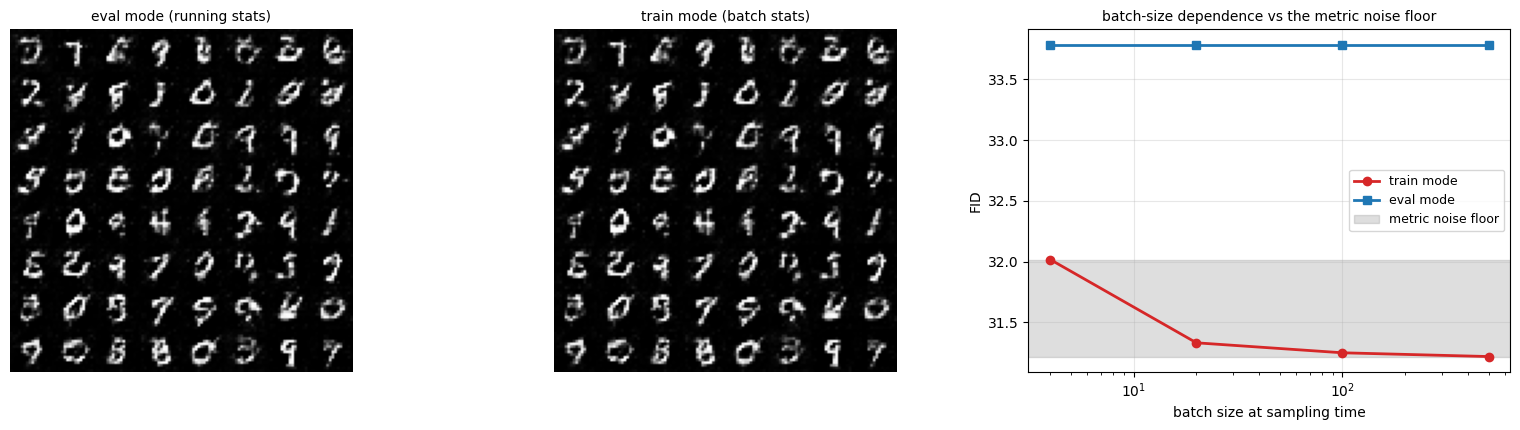

In [14]:
# ============================================================
# 図: train / eval の差
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (ttl, tm) in zip(axes[:2], [("eval mode (running stats)", False),
                                    ("train mode (batch stats)", True)]):
    restore_bn(G0, buf0)          # ★ 毎回復元する（train モードは移動平均を書き換える）
    S = sample_images(G0, n=64, train_mode=tm)
    grid = S.reshape(8, 8, 16, 16).permute(0, 2, 1, 3).reshape(128, 128)
    ax.imshow(grid.numpy(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(ttl, fontsize=10)
    ax.axis("off")

ax = axes[2]
bss = [r[0] for r in bs_rows]
ax.plot(bss, [r[1] for r in bs_rows], "o-", lw=2, color="tab:red", label="train mode")
ax.plot(bss, [r[2] for r in bs_rows], "s-", lw=2, color="tab:blue", label="eval mode")
ax.set_xscale("log")
ax.set_xlabel("batch size at sampling time")
ax.set_ylabel("FID")
ax.axhspan(min(ev.min(), tr.min()), min(ev.min(), tr.min()) + FLOOR,
           color="tab:gray", alpha=0.25, label="metric noise floor")
ax.set_title("batch-size dependence vs the metric noise floor", fontsize=10)
ax.legend(fontsize=9)
restore_bn(G0, buf0)
plt.tight_layout()
plt.show()

### 読み取れること

#### 雑音床を先に測ったら、予測は当たっていた

| | 値 |
|---|---|
| eval モードで乱数の種だけ変えた FID | 32.989 〜 33.783 |
| **n=5000 での FID の標本誤差（幅）** | **0.793**（標準偏差 0.241） |
| eval 33.783 と train 31.219 の差 | **2.564** |

モード差 2.564 は雑音床 0.793 の **3.2 倍**なので、**検出できます**。
`train()` でサンプリングすると FID が 2.564 良く出る
（判別器が学習中に見ているのはこちら側です）。

#### ただし train モードのサンプリングは**モデルを書き換える**

ここで本章でいちばん危険な罠を踏みました。

| 手順 | FID | 備考 |
|---|---|---|
| 1. eval でサンプリング | 33.783 | 移動平均は変化しない |
| 2. train でサンプリング | 31.219 | **移動平均が 6/6 個のバッファで変化** |
| 3. もう一度 eval | **31.989** | 1 との差 **1.794**（雑音床 0.793 の 2.3 倍） |
| 4. 移動平均を復元して eval | **33.783** | 1 との差 **0.000** |

`train()` モードで 10 バッチ流しただけで、BatchNorm の移動平均が
生成サンプルの統計量に置き換わります。**その後の eval の測定が 1.794 ずれます。**
手順4 で厳密に元の値に戻るので、原因は確定です。

これは「学習中は良く見えるのに保存して読み込むと崩れる」の**逆**でもあります。
`train()` で一度サンプリングしたモデルを保存すると、
**保存されるのは学習で溜めた移動平均ではなく、サンプリング時の統計量**です。

> 生成器を `train()` モードで動かすときは、BatchNorm のバッファを
> 保存・復元する。さもないと、以降の測定もチェックポイントも汚染されます。

#### バッチサイズ依存は、復元してから測ると小さい

| バッチ | train モード | eval モード |
|---|---|---|
| 500 | 31.219 | 33.783 |
| 100 | 31.250 | 33.783 |
| 20 | 31.332 | 33.783 |
| 4 | 32.017 | 33.783 |

eval 列の幅は **0.000** です。移動平均はバッチサイズに依らないので当然ですが、
**復元が正しく効いていることの確認**になります。

train 列の幅は 0.798 で、**雑音床 0.793 とほぼ同じ**。
バッチ 500 → 20 の差は雑音以下で、バッチ 4 でようやく 32.017 に上がります。
**この設定ではバッチサイズ依存はほとんど無い**と読むべきです。

#### 対照列の散らばりは、まず汚染を疑う

最初の実装ではバッファを復元していませんでした。そのときの eval 列は
幅 **2.040** で散らばり、「これが雑音床だ」と読み違えました。
しかし本当の雑音床は 0.793 で、差の 1.2 以上は**汚染**でした。

> 「定数になるはずの対照列」が散らばったとき、
> それを雑音床と読む前に**副作用が無いか**を確かめる。
> 雑音なら乱数の種だけを変えても同じ幅が出るはずです（本節の (1)）。

<a id="pitfalls"></a>
## 7. 実装でつまずいた点

### (1) FID の基準値が、参照データの並べ方だけで 27 倍変わった

第3節に書いたとおりです。`X_test[:5000]` を参照にすると、
同じテストセットの後半（= 完璧なモデルに相当）が FID **12.99**、
学習データのほうが **5.21** という逆転が起きました。

原因は MNIST のテストセットが均質でないこと。
前半の分類精度 0.9712 に対し後半 0.9884 で、**書き手の構成が違います**。
クラス構成はほぼ同じ（最大偏差 0.0142 / 0.0128）なのでクラスの偏りではありません。

並べ替えてから分けると FID は **0.4740**。27 倍の差です。

**教訓**: 参照データは必ず無作為化する。公開データセットの既定の順序を信用しない。
そして雑音床（完璧なモデルが出す値）を自分で測る。

### (2) 死んだ ReLU で共分散が特異になり、行列平方根が信用できなくなる

特徴は分類器の 64 次元 ReLU 出力です。このうち **25 次元が常に厳密にゼロ**でした
（全要素の 50.7% がゼロ）。すると共分散行列が特異になります。

| | 値 |
|---|---|
| 最大固有値 | 123.3808 |
| **最小固有値** | **$-1.96\times10^{-14}$（負）** |
| 条件数 | $1.2\times10^{32}$ |

固有値が負になるのは丸め誤差です。この状態で $(\Sigma_1\Sigma_2)^{1/2}$ を計算すると
`scipy` が `Matrix is singular` と警告し、値が信用できません。

**ただしこれは (1) の原因ではありませんでした。** 特徴を 64 → 32 → 16 → 8 次元に
射影しても逆転は残りました（12.99 / 12.85 / 11.28 / 8.06 対 5.21 / 5.14 / 4.45 / 3.16）。
2つの問題を**順番に**切り分ける必要がありました。

**教訓**: 警告が出ている箇所と、症状の原因は別のことがある。
警告を直して症状が消えるか確認するまで、原因と呼ばない。

### (3) 壁時計時間は実行環境の混み具合で 16 倍変わる

同一の学習（1000 歩）を測ったところ、

| 状況 | 1000 歩の時間 |
|---|---|
| 単独で実行 | **66 秒** |
| 他の実験と並行 | **1057 秒** |

**16 倍**です。本章の総実行時間を「約 2472 秒」と書いても、
別のマシン・別の状況では意味を持ちません。

**教訓**: 壁時計時間は実装の比較に使えない。
比較したいなら、同じプロセスの中で連続して測る。

### (4) train モードでサンプリングすると、以降の測定が汚染される

第6節で詳しく測りました。`train()` モードで 10 バッチ流すだけで
BatchNorm の移動平均が 6/6 個のバッファで書き換わり、
その後の eval の FID が 33.783 → 31.989（**1.794** のずれ、雑音床 0.793 の 2.3 倍）。
バッファを復元すると厳密に 33.783 に戻ります。

最初の実装では復元していなかったので、
「定数になるはずの eval 列が幅 2.040 で散らばった」のを**雑音床と読み違えました**。
本当の雑音床は 0.793（乱数の種だけを変えて測る）で、残りは汚染でした。

**教訓**: 「定数になるはずの対照列」が散らばったら、
雑音と読む前に**副作用**を疑う。雑音なら、乱数の種だけを変えても同じ幅が出ます。

<a id="summary"></a>
## 8. まとめとチートシート

### 測った数値

| 問い | 答え | 根拠 |
|---|---|---|
| 転置畳み込みの市松模様は学習前に決まるか | **重なりの一様性は学習前に厳密に決まる**（$k$ が $s$ の倍数なら比 1.00、でなければ 2.25〜4.00） | 重みを 1 に固定して直接測った |
| その計算は学習後の模様を予測するか | **しない**。$k=4$（比 1.00）が stride 判別器で 0.05366、$k=3$（比 4.00）の 0.02080 より **2.6 倍悪い** | 6組の交差実験 |
| では市松模様を決めているのは何か | **判別器の縮小方法**。生成器を変えずに stride → MaxPool にすると 0.05366 → 0.00447（**12 倍**） | ストライド畳み込みは固定の偶奇格子しか見ないので罰を与えられない |
| 補間 + conv は効くか | **効く**。市松 0.00101 で真のデータの 0.00187 を下回り、FID 15.952 で最良 | ただし「偶奇を混ぜるから」と読むべき |
| DCGAN の BatchNorm は効くか | **効く**。外すと G で 1.7 倍、**D で 2.3 倍**悪化。判別器側のほうが効く | 2シード、範囲が重ならない |
| 全結合の隠れ層を足すと | **9.1 倍悪化**（FID 301.5、占有率の最大偏差 0.3100） | |
| 判別器を ReLU にすると（ガイドライン5違反） | 1000歩で **1.9 倍良い**（17.1 対 33.2）。2500歩でも残るが **1.5 倍**に縮む | 2シード |
| 判別器を MaxPool にすると（ガイドライン1違反） | 1000歩で 1.7 倍良いが、**2500歩では基準と区別できない**（11.83 対 10.37、範囲が重なる） | 序盤を速くするだけ |
| FID の基準値はどう決まるか | 参照データの**並べ方**で 12.99 → 0.4740（**27 倍**）変わる。MNIST のテストセットは前半後半で書き手が違う | 精度 0.9712 対 0.9884 |
| この指標でどこまで細かい差を読めるか | **幅 0.793**（n=5000、乱数の種だけを変えた散らばり）。これより小さい差は読めない | eval モードで種を6通り |
| BatchNorm の train / eval 差は検出できるか | **できる**。2.564（雑音床の 3.2 倍）。ただし train モードのサンプリングは**移動平均を書き換える**ので、以降の測定が 1.794 汚染される | 復元すると厳密に元の値 |

### 画像の GAN を測るときのチェックリスト

| やること | 理由 |
|---|---|
| 参照データを**無作為化**する | 既定の順序が均質とは限らない（27 倍の差） |
| **雑音床**を測る（乱数の種だけを変えて散らばりを見る） | それより小さい差は報告できない（本章では 0.793） |
| サンプリングの乱数を**固定**する | さもないと表に書いた数値が再実行で ±0.8 動く |
| 分散ゼロの特徴次元を**落とす** | 共分散が特異になり行列平方根が信用できない（条件数 $10^{32}$） |
| `train()` モードで動かすなら BatchNorm のバッファを**保存・復元** | 移動平均が書き換わり、以降の測定とチェックポイントが汚染される |
| 指標を**複数**見る | FID と占有率で順位が入れ替わる。確信度は崩壊を見逃す |
| シードを**2つ以上**回し、範囲で判断する | 182 の教訓 |
| **収束させてから**比べる | 1000歩での順位は 2500歩で変わる（F は逆転が消えた） |
| 画像サイズを 2 のべき乗にする | 全層で $k$ が $s$ の倍数になる |

### 他の章との接続

| 章 | 本章との関係 |
|---|---|
| **182** | 占有率・FID の思想をそのまま画像へ持ち込んだ。「1つの指標で順位を決めない」が再現した |
| **183** | 「標準値を疑う」が DCGAN のガイドラインでも成り立った（5つのうち2つが規模・学習量に依存） |
| **184** | 雑音床を測る規律。本章では参照データの並べ方で雑音床が 27 倍動き、さらに対照列の散らばりを汚染と読み分ける必要があった |
| **113（BatchNorm）** | train / eval の統計量の違いが生成に出る例。副作用でモデルが書き換わることまで含む |
| **185 ProGAN / StyleGAN** | 段階的成長は「低解像度から順に収束させる」手法。本章の「収束前の順位は読めない」と直結する |
| **186 VQ-GAN** | 判別器が何を見られるかが生成物を決める、という本章の結論がパッチ判別器の設計理由になる |

### 次章へ

185（ProGAN / StyleGAN）では解像度を段階的に上げます。
本章で測った「判別器が見られないものは直らない」は、
なぜ低解像度から順に学習させるのかの説明にそのまま使えます。

<a id="quiz"></a>
## 9. 自己評価クイズ

1. $k=3$, $s=2$ の転置畳み込みで、出力の重なり回数が 1, 2, 4 の3通りになった。
   なぜ 3 通りなのか、$k$ と $s$ から説明せよ。

2. 「$k$ が $s$ の倍数なら市松模様は出ない」は正しいか。本章の数値で答えよ。

3. 生成器を1つも変えずに、判別器の縮小方法を stride から MaxPool に替えると
   市松指標が 12 倍落ちた。機構を説明せよ。

4. MNIST のテストセットの前半を参照にすると、後半の FID が 12.99、
   学習データの FID が 5.21 になった。原因の候補を2つ挙げ、
   どちらが本当の原因かを切り分ける方法を述べよ。

5. ある2構成の FID が 55.7 と 301.5 だった。分類器の平均確信度は 0.7725 と 0.7729 で
   ほぼ同じだった。確信度が何を見落としているか述べよ。

6. 1000歩の学習で構成 D が基準より 1.9 倍良かった。2500歩では 1.5 倍、
   構成 F は 1.7 倍良かったのが基準と区別できなくなった。
   短い学習での比較から何を言ってよく、何を言ってはいけないか。

7. DCGAN のガイドライン5つのうち2つは、本章の設定では破ったほうが良かった。
   「DCGAN のガイドラインは間違っている」と書いてよいか。どう書くべきか。

8. 特徴の 64 次元のうち 25 次元が常にゼロだった。これが FID に与える影響を述べよ。
   また、この問題を直しても残った症状は何だったか。

9. まったく同一の学習（同じシード・同じ結果）が 66 秒と 1057 秒で終わった。
   実行時間を教材に書くとき、何を添えるべきか。

10. 「定数になるはずの対照列」が散らばった。雑音床だと読んでよいか。
    読み違えを防ぐ確認手順を述べよ。

11. 画像の生成モデルを1つの数値で評価せよと言われたら何を使うか。
    その数値が保証しないことを3つ挙げよ。

---

### 解答の指針

1. 出力の画素位置 $i$ に足し込まれる回数は $\lceil (k - (i \bmod s))/s \rceil$ で、
   $i \bmod s$ の値（$s$ 通り）で決まる。2次元なので縦横の積になり、
   $k=3, s=2$ では $\{1, 2\} \times \{1, 2\} = \{1, 2, 4\}$ の3通り。

2. **正しくない。** 一様な重なりが保証するのは「学習ゼロの状態で模様が無い」ことだけ。
   stride 判別器のもとでは $k=4$（比 1.00）が 0.05366 で、
   $k=3$（比 4.00）の 0.02080 より 2.6 倍悪かった。
   学習後の重みは一様な重なりの上に模様を作れる。

3. ストライド 2 の畳み込みは入力の固定された偶奇格子の上だけを見るので、
   偶奇で明るさが 0.059 違っても受容野の中で見分けられない。
   **罰を与えられないものは直らない。** MaxPool は 2x2 で偶奇をまたぐので差が伝わる。

4. 候補1: 特徴の共分散が特異（25/64 次元がゼロ、条件数 $10^{32}$）。
   候補2: テストセットが均質でない。
   切り分けは、特徴を低次元に射影して逆転が消えるかを見る。
   本章では 64 → 8 次元でも逆転が残ったので候補1 は原因でなかった。
   分類精度（0.9712 対 0.9884）で候補2 を確認した。

5. 確信度は「はっきりした数字に見えるか」しか見ない。
   1クラスだけを綺麗に出すモデルは確信度が高い（占有率の最大偏差 0.3100）。
   モードの被覆を見落とす。182 の FID の盲点と同じ型。

6. 言ってよいのは「1000歩の時点では D が良い」。
   言ってはいけないのは「D のほうが良い構成である」。
   改善の比が構成ごとに 1.70〜3.21 倍と違うので、打ち切る位置で順位が変わる。

7. 書いてはいけない。原論文は 64x64 の LSUN / ImageNet で、
   はるかに長く学習して得た経験則。本章は 16x16 の MNIST。
   「この規模では2つが逆転した」と条件付きで書く。
   さらに F の逆転は 2500歩で消えたので、**規模と学習量の両方**に依存する。

8. 共分散が特異になり、最小固有値が負（$-1.96\times10^{-14}$）になって
   $(\Sigma_1\Sigma_2)^{1/2}$ の計算が信用できなくなる。分散ゼロの次元を落とせば直る。
   残った症状は FID の基準値の逆転で、原因はテストセットの非均質性だった。

9. 測った状況（単独実行か並行実行か）と、マシンの種類。
   実装 A と B を比べるなら、同じプロセスの中で連続して測る。
   壁時計時間そのものは再現しない。

10. 1つなら特徴空間の FID（参照は無作為化し、雑音床を併記する）。
    保証しないこと: (a) モードの被覆（占有率は別に測る）、
    (b) 偶奇のような局所的な模様（市松指標は FID でほぼ動かない）、
    (c) 特徴抽出器が見ない性質（本章の分類器は数字の識別に必要な特徴しか持たない）。